# 临时实验：2PCF旧卷积表达式与新配对表达式

从 `corr2pcf.ipynb` 的 **2. Direct low-level reconstruction of $\xi(s)$** 抽出。
本实验独立保存，原 notebook 不变。适用于实验分支 `codex/2pcf-pair-expression`。

先在这个工作树根目录执行 `python -m pip install -e ".[plot]"`，并使用同一解释器、重启 notebook kernel。
从项目根目录、`examples/` 或 `examples/notebooks/` 均可运行。这里是单进程/多线程对比，不用 MPI 启动。

旧式：`((delta @ W) * delta).as_array().mean() / RR`。
新式：先 `pair = delta.pair_with(delta)`，再 `pair @ W / RR`；完整曲线可用 `pair.evaluate(windows) / RR`。
**配对对象返回系数数组的配对均值，不会自动除以RR。**

默认读取已投影的真实J=8 halo场，保留原小节的 sphere-R5 平滑和0到150的26个薄球壳采样。
也保留可选的重新投影开关。投影、文件读取及共同平滑单独计时，不混入三种曲线计算的速度比较。


In [1]:
from pathlib import Path
from time import perf_counter
from datetime import datetime, timezone
import copy
import gc
import hashlib
import json
import os
import platform
import subprocess

import matplotlib.pyplot as plt
import numba
import numpy as np
import scipy
from IPython.display import Markdown, display

import pyhermes
from pyhermes.base.sfc_projection import SFCProjection
from pyhermes.io import SFCField, WindowFunc
from pyhermes.param.parambase import read_param
from pyhermes.utils.mpi_util import MPI

cwd = Path.cwd().resolve()
if cwd.name == "notebooks" and cwd.parent.name == "examples":
    PROJECT_ROOT = cwd.parent.parent
elif cwd.name == "examples":
    PROJECT_ROOT = cwd.parent
elif (cwd / "examples").is_dir():
    PROJECT_ROOT = cwd
else:
    raise RuntimeError("Run from the project root, examples/, or examples/notebooks/.")
EXAMPLES_DIR = PROJECT_ROOT / "examples"
OUTPUT_DIR = EXAMPLES_DIR / "output"
os.chdir(EXAMPLES_DIR)
if not hasattr(SFCField, "pair_with"):
    raise RuntimeError("Install this experiment checkout and restart the kernel: python -m pip install -e '.[plot]'")
if MPI.COMM_WORLD.Get_size() != 1:
    raise RuntimeError("Run this notebook as one process; high-level Corr_2PCF handles distributed tasks.")

THREADS = min(8, numba.config.NUMBA_NUM_THREADS)  # 可自行调整
REPEATS = 3                                  # 同一kernel内重复；不是3个新进程
REPROJECT = False                            # True: 按原小节从catalogue重新投影
SFC_PATH = OUTPUT_DIR / "quijote8000_snap004_sfc.pkl"
s_direct = np.linspace(0.0, 150.0, 26)
SMOOTH_R = 5.0
RTOL, ATOL = 1e-8, 1e-11
print("Imported code:", Path(pyhermes.__file__).resolve())
print("Threads:", THREADS, "repeats:", REPEATS, "samples:", len(s_direct))


Imported code: /Users/xutengpeng/.codex/worktrees/2pcf-optimization/PyHermes/pyhermes/__init__.py
Threads: 8 repeats: 3 samples: 26


## 1. 相同输入、反差场和平滑

$$\rho=\langle D\rangle,\qquad RR=\rho^2,\qquad
\Delta D_w=(D-\rho)@W_{\rm sphere}(5).$$

`REPROJECT=False` 时先运行已有 Quick Start 生成输入场；输入不存在会给出提示，不会自动提交服务器任务。
下面的共同准备只做一次，三种方法共享完全相同的 `deltaD_w` 和 `RR`。


In [2]:
t0 = perf_counter()
if REPROJECT:
    projection_params = read_param("./configs/param_sfc_projection.yaml")
    projection_params["SFCProjection"]["threads"] = THREADS
    D = SFCProjection(projection_params).run(save_result=False)
else:
    if not SFC_PATH.is_file():
        raise FileNotFoundError(f"{SFC_PATH}: run Quick Start first, or set REPROJECT=True.")
    D = SFCField(data_path=str(SFC_PATH), threads=THREADS)
D.threads = THREADS
input_seconds = perf_counter() - t0
t0 = perf_counter()
rho = D.field_mean_density(value_unit="grid")
RR = rho ** 2
if not np.isfinite(RR) or RR <= 0:
    raise ValueError("This uniform-reference demonstration requires a finite nonzero mean density.")
deltaD = D - rho
W_smooth = WindowFunc({"type": "sphere", "len_args": {"R": SMOOTH_R}}, D.sfc_info, threads=THREADS)
deltaD_w = deltaD @ W_smooth
common_prepare_seconds = perf_counter() - t0
print(f"J={D.J}, grid={D.epsilon.shape}, rho={rho:.8e}, RR={RR:.8e}")
print(f"Input/projection: {input_seconds:.6f} s; common contrast/smoothing: {common_prepare_seconds:.6f} s")


00:32:26 - INFO - pyhermes.io.base:SFCField - Reading SFCField data from ---> /Users/xutengpeng/.codex/worktrees/2pcf-optimization/PyHermes/examples/output/quijote8000_snap004_sfc.pkl <---


00:32:26 - INFO - pyhermes.io.base:SFCField - epsilon: Shape(256, 256, 256), Min = -3.215e-06, Max = 1.343e-05, Mean = 5.96e-08, Sum = 1


J=8, grid=(256, 256, 256), rho=5.96046448e-08, RR=3.55271368e-15
Input/projection: 0.284279 s; common contrast/smoothing: 2.238608 s


## 2. 三种写法

`xi_at_s` 保留原小节的计算定义。新接口使用相同窗口和归一化：

```python
with deltaD_w.pair_with(deltaD_w) as pair:
    xi_one = (pair @ W_shell) / RR
    xi_curve = pair.evaluate(windows) / RR
```

配对对象在创建时准备一次FFT/配对权重。逐点调用复用这些权重；批量调用还可以共享精确径向分组等窗口计划。
配对对象存活期间不要原地改动输入数组。退出 `with` 即释放其缓存。


In [3]:
def xi_at_s(delta_field, s, RR, threads=THREADS):
    """Original section: evaluate the shell-binned 2PCF at one separation."""
    W_shell = WindowFunc(
        {"type": "shell", "len_args": {"R": float(s)}},
        delta_field.sfc_info,
        threads=threads,
    )
    local_pair_product = (delta_field @ W_shell) * delta_field
    return float(local_pair_product.as_array().mean() / RR)


def shell_windows(field, radii):
    return [WindowFunc({"type": "shell", "len_args": {"R": float(s)}},
                       field.sfc_info, threads=THREADS) for s in radii]


def run_curve(method, field, radii, reference):
    """Every call makes fresh windows and, for a new path, a fresh pair."""
    started = perf_counter()
    setup = 0.0
    metrics = {}
    if method == "old expression":
        query_started = perf_counter()
        curve = np.array([xi_at_s(field, s, reference) for s in radii])
        query = perf_counter() - query_started
    else:
        setup_started = perf_counter()
        with field.pair_with(field, threads=THREADS) as pair:
            setup = perf_counter() - setup_started
            query_started = perf_counter()
            windows = shell_windows(field, radii)  # construction is inside query time
            if method == "pair @ window loop":
                curve = np.array([pair @ w for w in windows]) / reference
            elif method == "pair.evaluate batch":
                curve = pair.evaluate(windows) / reference
            else:
                raise ValueError(method)
            query = perf_counter() - query_started
            metrics = pair.metrics
    total = perf_counter() - started  # includes pair setup and cleanup
    return curve, dict(method=method, setup_seconds=setup, query_seconds=query,
                       total_seconds=total, metrics=metrics)

METHODS = ("old expression", "pair @ window loop", "pair.evaluate batch")


## 3. 小网格预热，再比较完整曲线

这里先用小网格触发相关JIT编译，预热耗时单独打印。随后在同一kernel里轮换执行顺序，每次都重新创建窗口和配对对象。
**新方法的总时间包含其FFT/配对准备**；不会拿准备完成后的单次查询时间与旧方法完整曲线时间比较。

这不是冷启动测试：OS/编译缓存未清空。它也是本机、单进程、多线程的交互测试，不能代替服务器的独立进程/同分配测速。


In [4]:
def tiny_field(seed=1):
    value = SFCField(threads=THREADS)
    value.sfc_info = dict(J=3, L=8, V=64.**3, box_size=64., scale_factor=.125,
                          phi_resolution=64, wavelet_mode="db2", wavelet_level=6,
                          field_kind="derived_field", weight_normalization="catalog",
                          field_integral=1.)
    value.epsilon = np.random.default_rng(seed).normal(size=(8, 8, 8))
    value.format_sfc_params()
    return value

t0 = perf_counter()
warm_field = tiny_field()
for method in METHODS:
    run_curve(method, warm_field, np.array([0., 3., 6., 9.]), 1.)
warmup_seconds = perf_counter() - t0
del warm_field
print(f"Small-grid warmup, excluded from the table: {warmup_seconds:.6f} s")

records = []
curves = {}
for repeat in range(REPEATS):
    order = METHODS[repeat % len(METHODS):] + METHODS[:repeat % len(METHODS)]
    for method in order:
        gc.collect()  # outside the timed interval
        curve, record = run_curve(method, deltaD_w, s_direct, RR)
        record["repeat"] = repeat + 1
        records.append(record)
        if method in curves:
            np.testing.assert_allclose(curve, curves[method], rtol=RTOL, atol=ATOL)
        curves[method] = curve
        print(f"repeat {repeat+1}: {method:24s} total={record['total_seconds']:.6f} s")

for method in METHODS[1:]:
    np.testing.assert_allclose(curves[method], curves[METHODS[0]], rtol=RTOL, atol=ATOL)
    print(method, "max |delta xi|:", np.max(np.abs(curves[method] - curves[METHODS[0]])))


Small-grid warmup, excluded from the table: 1.815116 s


repeat 1: old expression           total=7.932878 s


repeat 1: pair @ window loop       total=2.541946 s


repeat 1: pair.evaluate batch      total=0.431308 s


repeat 2: pair @ window loop       total=2.104833 s


repeat 2: pair.evaluate batch      total=0.395015 s


repeat 2: old expression           total=5.335687 s


repeat 3: pair.evaluate batch      total=0.346891 s


repeat 3: old expression           total=5.260787 s


repeat 3: pair @ window loop       total=2.066135 s
pair @ window loop max |delta xi|: 9.769962616701378e-15
pair.evaluate batch max |delta xi|: 3.2862601528904634e-14


## 4. 计时表与曲线

总时间为每种方法所有重复中的最小值，同时保留中位数、范围和全部原始记录。
准备/查询两列来自**同一个最快总时间样本**，没有分别挑选各阶段最小值后相加。
总时间还包含上下文退出和少量调度开销，所以不强行令准备加查询等于总时间。
共同的输入读取、投影、反差构建和平滑不在此表内，前面已单列。


|Method|Pair setup / s|Curve query / s|Total min / s|Total median / s|Total range / s|
|---|---:|---:|---:|---:|---:|
|old expression|0.000000|5.260777|5.260787|5.335687|5.260787--7.932878|
|pair @ window loop|0.036598|2.028617|2.066135|2.104833|2.066135--2.541946|
|pair.evaluate batch|0.037022|0.309016|0.346891|0.395015|0.346891--0.431308|

Observed minimum-total ratio old/pair @ window loop: 2.546
Observed minimum-total ratio old/pair.evaluate batch: 15.166


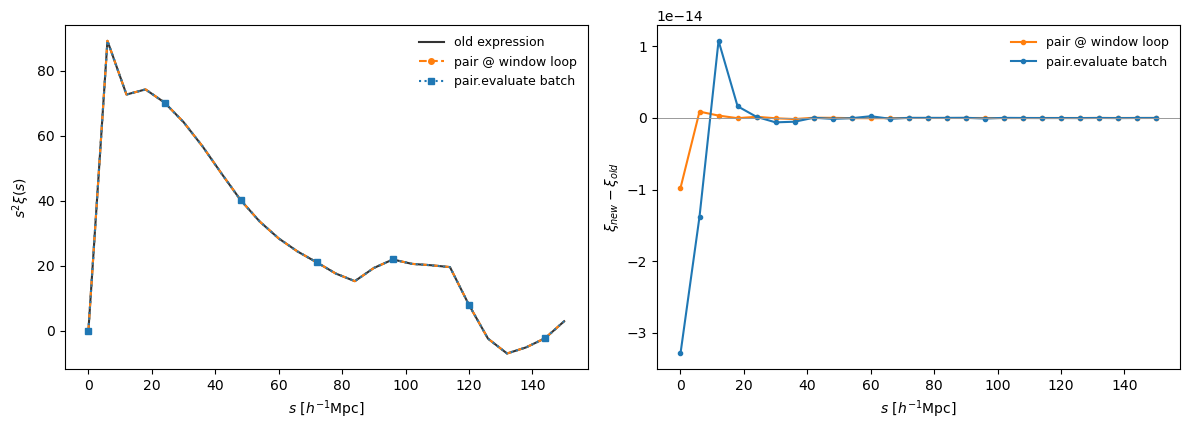

In [5]:
best = {}
table = ["|Method|Pair setup / s|Curve query / s|Total min / s|Total median / s|Total range / s|",
         "|---|---:|---:|---:|---:|---:|"]
for method in METHODS:
    samples = [r for r in records if r["method"] == method]
    chosen = min(samples, key=lambda r: r["total_seconds"])
    best[method] = chosen
    totals = [r["total_seconds"] for r in samples]
    table.append(f"|{method}|{chosen['setup_seconds']:.6f}|{chosen['query_seconds']:.6f}|"
                 f"{min(totals):.6f}|{np.median(totals):.6f}|{min(totals):.6f}--{max(totals):.6f}|")
display(Markdown("\n".join(table)))
for method in METHODS[1:]:
    print(f"Observed minimum-total ratio old/{method}: "
          f"{best[METHODS[0]]['total_seconds']/best[method]['total_seconds']:.3f}")

fig, (ax, residual) = plt.subplots(1, 2, figsize=(12, 4.4))
styles = [("0.2", "-", None), ("#ff7f0e", "--", "o"), ("#1f77b4", ":", "s")]
for method, (color, line, marker) in zip(METHODS, styles):
    ax.plot(s_direct, s_direct**2 * curves[method], color=color, ls=line,
            marker=marker, markevery=4, ms=4, label=method)
for method, color in zip(METHODS[1:], ("#ff7f0e", "#1f77b4")):
    residual.plot(s_direct, curves[method]-curves[METHODS[0]], color=color, marker=".", label=method)
ax.set(xlabel=r"$s\ [h^{-1}\mathrm{Mpc}]$", ylabel=r"$s^2\xi(s)$")
residual.set(xlabel=r"$s\ [h^{-1}\mathrm{Mpc}]$", ylabel=r"$\xi_{new}-\xi_{old}$")
ax.legend(frameon=False, fontsize=9)
residual.legend(frameon=False, fontsize=9)
residual.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
residual.axhline(0, color="0.6", lw=.7)
fig.tight_layout()
plt.show()


## 5. 两个不同的实数场：虚部会不会丢信息？

不同场的 $A^*B$ 一般确实有虚部，它编码交叉相关中随分离方向反转而变号的部分。
实数场满足 $Z(-\mathbf{k})=Z(\mathbf{k})^*$。对于薄球壳等实、偶窗口，$+\mathbf{k}$ 和
$-\mathbf{k}$ 的虚部贡献相消，所以计算这种窗口平均只需实部。这个结论不要求两个场相同。

有方向的位移/导数或其他复响应窗口则可能需要虚部。实验接口遇到复窗口时回到完整卷积，保留相位和操作数顺序。
下面用相差90度的cos/sin场及软件自带的方向导数窗口展示：对称配对接近0，方向导数配对非零；新旧结果应一致。


In [6]:
A = tiny_field()
B = tiny_field(2)
phase = 2*np.pi*np.indices(A.epsilon.shape)[0]/A.L
A.epsilon = np.cos(phase)
B.epsilon = np.sin(phase)
Z = np.fft.rfftn(A.epsilon).conj() * np.fft.rfftn(B.epsilon)
print("max |Re(A* B)|:", np.max(np.abs(Z.real)))
print("max |Im(A* B)|:", np.max(np.abs(Z.imag)))
W_even = WindowFunc({"type": "shell", "len_args": {"R": 3.}}, A.sfc_info, threads=THREADS)
W_odd = WindowFunc({"type": "directional_derivative", "len_args": {},
                    "los_args": [1., 0., 0.]}, A.sfc_info, threads=THREADS)
old_even = ((A @ W_even) * B).as_array().mean()
old_odd = ((A @ W_odd) * B).as_array().mean()
with A.pair_with(B) as cross:
    new_even = cross @ W_even
    new_odd = cross @ W_odd
    phase_metrics = cross.metrics
np.testing.assert_allclose([new_even, new_odd], [old_even, old_odd], rtol=1e-10, atol=1e-12)
assert abs(new_odd) > 1e-3
assert phase_metrics["fallback_convolution_count"] == 1
print("Symmetric shell (old, new):", old_even, new_even)
print("Directional derivative (old, new):", old_odd, new_odd)
print("Complex-response fallbacks:", phase_metrics["fallback_convolution_count"])


max |Re(A* B)|: 2.006461315723024e-12
max |Im(A* B)|: 65536.0


Symmetric shell (old, new): 2.7755575615628914e-17 1.5036601567217227e-17
Directional derivative (old, new): -0.38370504004830025 -0.38370504004830025
Complex-response fallbacks: 1


## 6. 保留本次全部测量

保存所有重复、曲线、输入指纹、导入源码位置和环境信息。这里只记录本机实际观察到的速度，不自动写入文章或正式性能表。
实验使用每次新建的配对对象；缓存没有跨重复复用整条曲线。


In [7]:
try:
    source_commit = subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT, text=True).strip()
    source_dirty = bool(subprocess.check_output(["git", "status", "--porcelain"], cwd=PROJECT_ROOT, text=True).strip())
except (FileNotFoundError, subprocess.CalledProcessError):
    source_commit, source_dirty = None, None
report = dict(
    source_commit=source_commit, source_dirty=source_dirty,
    imported_pyhermes=str(Path(pyhermes.__file__).resolve()),
    python=platform.python_version(), platform=platform.platform(),
    numpy=np.__version__, scipy=scipy.__version__, numba=numba.__version__,
    threads=THREADS, numba_threads=numba.get_num_threads(), mpi_ranks=1,
    J=D.J, grid_shape=list(D.epsilon.shape), box_size=D.box_size,
    input_mode="project" if REPROJECT else "saved", input_path=str(SFC_PATH),
    input_epsilon_sha256=hashlib.sha256(np.ascontiguousarray(D.epsilon).tobytes()).hexdigest(),
    smoothing_R=SMOOTH_R, sampling=s_direct.tolist(), rho=float(rho), RR=float(RR),
    input_seconds=input_seconds, common_prepare_seconds=common_prepare_seconds,
    warmup_seconds=warmup_seconds, repeats=REPEATS,
    timing="Same-kernel warm comparison; fresh pair/windows each repeat; total includes pair FFT setup and cleanup. Projection/input/common smoothing and audits/plotting excluded.",
    records=records, curves={k:v.tolist() for k,v in curves.items()},
    max_abs_xi_difference={k:float(np.max(np.abs(curves[k]-curves[METHODS[0]]))) for k in METHODS[1:]},
    phase_demo=dict(symmetric_old=float(old_even), symmetric_new=float(new_even),
                    directional_old=float(old_odd), directional_new=float(new_odd)),
)
REPORT_PATH = OUTPUT_DIR / ("tmp_pair_expression_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + ".json")
REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)
REPORT_PATH.write_text(json.dumps(report, indent=2) + "\n")
print("Saved all repetitions and provenance:", REPORT_PATH)


Saved all repetitions and provenance: /Users/xutengpeng/.codex/worktrees/2pcf-optimization/PyHermes/examples/output/tmp_pair_expression_20261017T163258806560Z.json
